# 时间序列检验：从问题走到 ADF、协整与 ECM

> 先看 OLS 在哪里可能失灵，再选择检验或修正；不要把缩写当成一串孤立公式。

本课把 BG、DW、NW、FGLS、DF/ADF、AEG 和 ECM 放在同一条侦查路线中。前四者首先面对回归误差的相关结构；DF/ADF 面对单一水平序列的单位根；AEG 与 ECM 面对两个非平稳变量的长期关系与回归路径。


## 0. 一张地图

| 看到的问题 | 对象 | 工具 | 接下来 |
|---|---|---|---|
| 残差像有记忆 | 回归误差 u | DW（窄场景）、BG | 改均值方程，或 NW/FGLS |
| 推断可能过度自信 | 误差协方差 | NW / HAC | 系数不变，重算稳健标准误 |
| 愿意为误差建模 | 协方差结构 | FGLS | 改变估计；结构设错有风险 |
| 水平像随机游走 | 单一序列 y | DF / ADF | 差分或协整分析 |
| 两个漂移变量是否有锚点 | 长期残差 | AEG | 残差平稳才说协整 |
| 偏离后怎样拉回 | 短期变化与长期偏离 | ECM | 估调整速度 |

一句话：BG/DW/NW/FGLS 先处理残差；DF/ADF 先处理单位根；AEG 检查共同趋势下的残差；ECM 描述偏离后的调整。


## 1. 第一个问题：OLS 的残差为什么让人不放心？

从一个熟悉的回归开始：

$$ y_t = \alpha + \beta x_t + u_t $$

若误差自身有记忆：

$$ u_t = \rho u_{t-1} + \varepsilon_t $$

今天的误差仍带着昨天的消息。OLS 系数未必立即无意义，但假定误差独立而算出的标准误可能太小，t 值会显得过于漂亮。


Common daily observations: 168
Fixed spread: SBLK - 0.28 × BHP
OLS beta for residual diagnostics: 0.290774


/tmp/ipykernel_3273627/1544570219.py:29: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  daily_prices = pd.read_sql(sql, conn, params=(PAIR_START, PAIR_END_EXCLUSIVE))


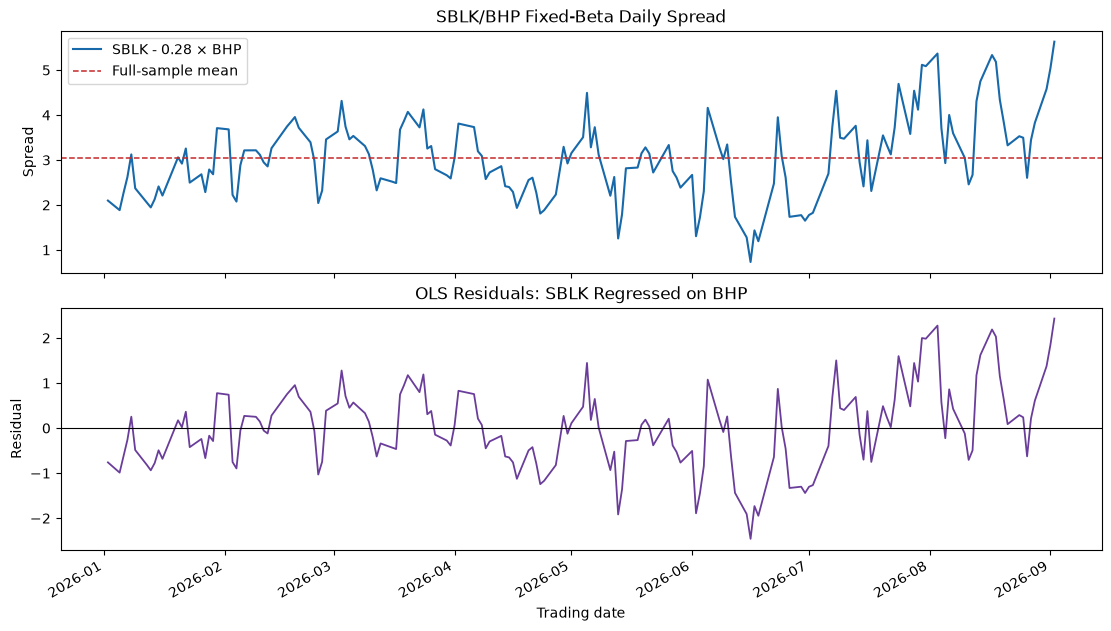

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymysql
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_breusch_godfrey
from statsmodels.tsa.stattools import adfuller, coint

# One shared daily data set for Sections 1--7.
PAIR_START = '2026-01-02'
PAIR_END_EXCLUSIVE = '2026-09-03'  # includes data through 2026-09-02
FIXED_BETA = 0.28
DB_CONFIG = {'host': '127.0.0.1', 'user': 'quant', 'password': '1q2w3e', 'database': 'quant_data'}
sql = '''
    SELECT DATE(p.time_utc) AS trade_date, p.ticker, p.price
    FROM us_market_prices AS p
    JOIN (
        SELECT ticker, DATE(time_utc) AS trade_date, MAX(time_utc) AS last_time
        FROM us_market_prices
        WHERE ticker IN ('SBLK', 'BHP')
          AND time_utc >= %s AND time_utc < %s
        GROUP BY ticker, DATE(time_utc)
    ) AS last_bar
      ON p.ticker = last_bar.ticker AND p.time_utc = last_bar.last_time
    ORDER BY trade_date, ticker
'''
conn = pymysql.connect(**DB_CONFIG)
try:
    daily_prices = pd.read_sql(sql, conn, params=(PAIR_START, PAIR_END_EXCLUSIVE))
finally:
    conn.close()

sblk_bhp = (daily_prices.pivot(index='trade_date', columns='ticker', values='price')
             .reindex(columns=['SBLK', 'BHP'])
             .dropna()
             .reset_index())
sblk_bhp['trade_date'] = pd.to_datetime(sblk_bhp['trade_date'])
sblk_bhp['spread'] = sblk_bhp['SBLK'] - FIXED_BETA * sblk_bhp['BHP']
assert sblk_bhp['trade_date'].min().strftime('%Y-%m-%d') == '2026-01-02'
assert sblk_bhp['trade_date'].max().strftime('%Y-%m-%d') == '2026-09-02'
print(f'Common daily observations: {len(sblk_bhp)}')
print(f'Fixed spread: SBLK - {FIXED_BETA:.2f} × BHP')

# This OLS is kept separate from the fixed-beta spread: it supplies the
# regression residuals used by the DW, BG and NW examples in Sections 1--3.
y = sblk_bhp['SBLK'].to_numpy()
x = sblk_bhp['BHP'].to_numpy()
ols = sm.OLS(y, sm.add_constant(x)).fit()
print(f'OLS beta for residual diagnostics: {ols.params[1]:.6f}')

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, constrained_layout=True)
axes[0].plot(sblk_bhp['trade_date'], sblk_bhp['spread'], color='#1769aa', lw=1.5, label='SBLK - 0.28 × BHP')
axes[0].axhline(sblk_bhp['spread'].mean(), color='#c62828', ls='--', lw=1.1, label='Full-sample mean')
axes[0].set(title='SBLK/BHP Fixed-Beta Daily Spread', ylabel='Spread')
axes[0].legend()
axes[1].plot(sblk_bhp['trade_date'], ols.resid, color='#6a3d9a', lw=1.3)
axes[1].axhline(0, color='black', lw=.8)
axes[1].set(title='OLS Residuals: SBLK Regressed on BHP', xlabel='Trading date', ylabel='Residual')
fig.autofmt_xdate()
plt.show()


## 2. 猜想：残差真的有序列相关吗？——DW 与 BG

DW 是一阶相关的快速提示，约等于 2 是“没有一阶相关”的参照；它不适合当万能裁判，尤其是模型含滞后因变量时。BG（Breusch-Godfrey）用辅助回归检验滞后残差是否共同有解释力，能检验到指定阶数 p。小 p-value 是反对“无相关”的证据，不是模型完全失效的判决。


In [3]:
dw = sm.stats.stattools.durbin_watson(ols.resid)
lm, lm_pvalue, _, _ = acorr_breusch_godfrey(ols, nlags=4)
print(f'DW = {dw:.3f}')
print(f'BG(4): LM = {lm:.3f}, p-value = {lm_pvalue:.4g}')


DW = 0.521
BG(4): LM = 91.982, p-value = 4.993e-19


## 3. 发现相关后，不要跳到唯一答案

先问是否漏掉了动力学、季节性或机制变量。随后有两条不同的推断路线：

- NW / HAC：保留 OLS 系数，用允许异方差和自相关的协方差矩阵重算标准误。
- FGLS：先估计误差相关结构，再做广义最小二乘；结构近似正确时有效率，猜错时会过度自信。

因此 NW 不是检验，而是稳健标准误；FGLS 不是“更高级的 NW”，而是更强的误差模型假设。


In [4]:
nw = ols.get_robustcov_results(cov_type='HAC', maxlags=4)
table = pd.DataFrame({'coefficient': ols.params, 'OLS SE': ols.bse,
                      'NW SE': nw.bse, 'OLS t': ols.tvalues, 'NW t': nw.tvalues},
                     index=['const', 'x'])
print(table.round(4))


       coefficient  OLS SE   NW SE    OLS t     NW t
const       2.1931  0.6332  1.0614   3.4637   2.0663
x           0.2908  0.0079  0.0141  36.8045  20.6583


## 4. 一个问题学懂 DF/ADF：偏离后，会不会回来？

先把公式放一边。假设某个 spread 平常在 **0** 附近；今天它突然变成 **+10**。从明天起，没有任何新消息。

有两种可能：

| 明天以及以后 | 这代表什么 | 交易直觉 |
|---|---|---|
| $+8, +6.4, +5.12, \ldots$ | 偏离每期缩小一点，最后回到 0 | 有均值回复 |
| $+10, +10, +10, \ldots$ | 这次偏离永远留下 | 没有均值回复 |

第二种情况就叫 **单位根（unit root）**。你暂时不用管“根”这个名称从哪来；只要记住：

$$ \text{unit root} = \text{一次冲击永久改变水平} $$

DF/ADF 的零假设就是故意先站在第二种、较保守的立场：

$$ H_0: \text{该序列有单位根，也就是冲击不会自己消失} $$

只有 p-value 很小时，我们才说：数据提供了足够证据，反对这个“冲击永久留下”的说法；也就是有均值回复的证据。p-value 大不是“证明没有均值回复”，只是不足以推翻零假设。

现在才看最小模型：

$$ y_t = \rho y_{t-1} + \varepsilon_t $$

把 $y_t$ 想成“离均值有多远”。$\rho$ 就是“昨天的偏离，今天还留下多少比例”。

- $\rho=0.8$：昨天偏离 +10，今天只剩 +8；它在回归。
- $\rho=1$：昨天偏离 +10，今天仍是 +10；它没有回归。这就是单位根。

DF 只是把同一个问题换一种写法：

$$ \Delta y_t = \gamma y_{t-1} + \varepsilon_t, \qquad \gamma = \rho - 1 $$

这里最关键的一行是：

$$ H_0: \gamma = 0 \quad \Longleftrightarrow \quad \rho = 1 $$

为什么？因为 $\gamma=0$ 时，昨天偏离得多高，对今天的变化没有任何“拉回”作用；这正是没有均值回复。若 $\gamma<0$，昨天越高，今天越倾向下跌一点；昨天越低，今天越倾向上涨一点。这才是均值回复。

ADF 只是在 DF 旁边再加入过去几期的变化，避免短期记忆干扰判断：

$$ \Delta y_t = c + \gamma y_{t-1} + \sum_{i=1}^{p} \phi_i \Delta y_{t-i} + e_t $$

所以 ADF 最终仍只在回答这一句：**你的 spread 被推离均值后，数据是否支持它有拉回来的力量？**


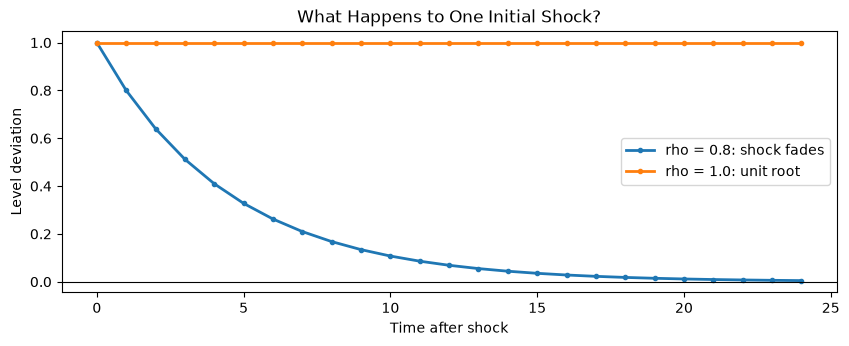

Common daily observations: 168
Fixed beta: 0.28


/tmp/ipykernel_3273627/4281962435.py:33: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  daily_prices = pd.read_sql(sql, conn, params=(PAIR_START, PAIR_END_EXCLUSIVE))


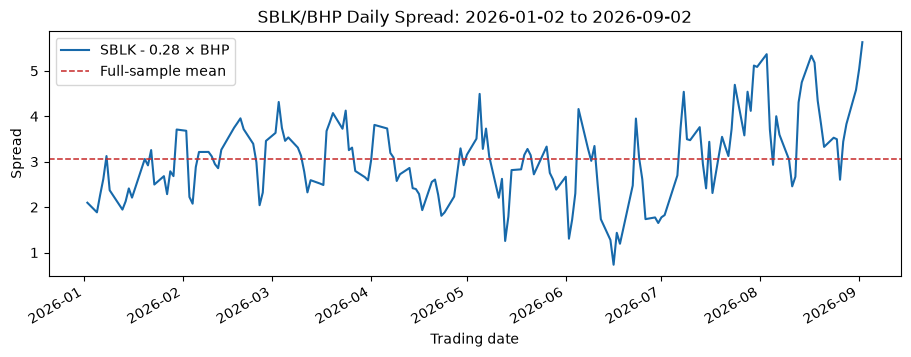

                       series  ADF statistic  p-value  lag  nobs
0  SBLK/BHP fixed-beta spread        -1.4585   0.5539    9   158


In [5]:
# One initial shock of +1; no new shocks after t=0.
steps = np.arange(25)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(steps, 0.8 ** steps, marker='o', ms=3, lw=2, label='rho = 0.8: shock fades')
ax.plot(steps, np.ones_like(steps), marker='o', ms=3, lw=2, label='rho = 1.0: unit root')
ax.axhline(0, color='black', lw=.8)
ax.set(title='What Happens to One Initial Shock?', xlabel='Time after shock', ylabel='Level deviation')
ax.legend()
plt.show()

# Real daily example: SBLK/BHP, last intraday price of each trading day.
import pymysql

PAIR_START = '2026-01-02'
PAIR_END_EXCLUSIVE = '2026-09-03'  # includes data through 2026-09-02
FIXED_BETA = 0.28
DB_CONFIG = {'host': '127.0.0.1', 'user': 'quant', 'password': '1q2w3e', 'database': 'quant_data'}
sql = '''
    SELECT DATE(p.time_utc) AS trade_date, p.ticker, p.price
    FROM us_market_prices AS p
    JOIN (
        SELECT ticker, DATE(time_utc) AS trade_date, MAX(time_utc) AS last_time
        FROM us_market_prices
        WHERE ticker IN ('SBLK', 'BHP')
          AND time_utc >= %s AND time_utc < %s
        GROUP BY ticker, DATE(time_utc)
    ) AS last_bar
      ON p.ticker = last_bar.ticker AND p.time_utc = last_bar.last_time
    ORDER BY trade_date, ticker
'''
conn = pymysql.connect(**DB_CONFIG)
try:
    daily_prices = pd.read_sql(sql, conn, params=(PAIR_START, PAIR_END_EXCLUSIVE))
finally:
    conn.close()

sblk_bhp = (daily_prices.pivot(index='trade_date', columns='ticker', values='price')
             .reindex(columns=['SBLK', 'BHP'])
             .dropna()
             .reset_index())
sblk_bhp['trade_date'] = pd.to_datetime(sblk_bhp['trade_date'])
sblk_bhp['spread'] = sblk_bhp['SBLK'] - FIXED_BETA * sblk_bhp['BHP']
assert sblk_bhp['trade_date'].min().strftime('%Y-%m-%d') == '2026-01-02'
assert sblk_bhp['trade_date'].max().strftime('%Y-%m-%d') == '2026-09-02'
print(f'Common daily observations: {len(sblk_bhp)}')
print(f'Fixed beta: {FIXED_BETA:.2f}')

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(sblk_bhp['trade_date'], sblk_bhp['spread'], color='#1769aa', lw=1.5, label='SBLK - 0.28 × BHP')
ax.axhline(sblk_bhp['spread'].mean(), color='#c62828', ls='--', lw=1.1, label='Full-sample mean')
ax.set(title='SBLK/BHP Daily Spread: 2026-01-02 to 2026-09-02', xlabel='Trading date', ylabel='Spread')
ax.legend()
fig.autofmt_xdate()
plt.show()

def adf_row(name, z):
    stat, pvalue, lag, nobs, *_ = adfuller(z, autolag='AIC', regression='c')
    return [name, stat, pvalue, lag, nobs]
series_for_adf = sblk_bhp['spread'].to_numpy()
print(pd.DataFrame([adf_row('SBLK/BHP fixed-beta spread', series_for_adf)],
                   columns=['series', 'ADF statistic', 'p-value', 'lag', 'nobs']).round(4))


### 4.1 DF 到 ADF：多出来的几项到底做什么？

先看 DF：

$$ \Delta y_t = c + \gamma y_{t-1} + e_t $$

它只用“昨天离均值多远”解释“今天改变多少”。但真实序列的短期变化有时自己也有记忆。例如昨天已经快速上涨，今天的变化可能仍受昨天这一下上涨影响；若忽略这种短期余波，残差 $e_t$ 还会有记忆，DF 的检验刻度就不可靠。

ADF 只是把这种短期余波单独控制住：

$$ \Delta y_t = c + \gamma y_{t-1} + \phi_1\Delta y_{t-1} + \phi_2\Delta y_{t-2} + \cdots + \phi_p\Delta y_{t-p} + e_t $$

读法是：在“昨天已经上涨/下跌了多少”这些短期信息都相同的条件下，昨天的**水平偏离** $y_{t-1}$ 是否仍会拉动今天的变化？

- $\phi_1,\ldots,\phi_p$：短期余波的控制变量；它们不是 ADF 想检验的主角。
- $\gamma$：控制完短期余波后，水平偏离带来的拉回力量；ADF 仍只检验 $H_0:\gamma=0$。

所以 ADF 没有换问题；它只是先把“短期惯性/短期反弹”从问题里拿掉，再判断长期是否存在单位根。

### 4.2 它与你的 rolling $\lambda$ 是什么关系？

你的 half-life 课使用带截距回归：

$$ \Delta S_t = a + \lambda S_{t-1} + \varepsilon_t $$

令均衡水平为 $\mu=-a/\lambda$，并定义偏离 $D_t=S_t-\mu$，同一条式子就是：

$$ \Delta D_t = \lambda D_{t-1} + \varepsilon_t $$

而把它还原成“今天的水平”写法：

$$ D_t = (1+\lambda)D_{t-1}+\varepsilon_t $$

因此，在**同一数据窗、都有截距、且 ADF 不加入滞后差分项**时：

$$ \boxed{\lambda=\gamma=\rho-1, \qquad \rho=1+\lambda} $$

它们不是两个相互竞争的回归力量：$\rho$ 说“昨天的偏离留下多少”；$\lambda=\gamma$ 说“昨天的偏离会令今天改变多少”。例如 $\rho=0.8$ 等价于 $\lambda=\gamma=-0.2$：偏离的 80% 留下，同时今天会向均值改变原偏离的 20%。

差别在用途：rolling $\lambda$ 是你在每个滚动窗口估计的**局部速度/half-life 参数**；ADF 的 $\gamma$ 是单位根检验回归里的**被检验系数**。ADF 加入 $\Delta S$ 的滞后项后，$\gamma$ 还是“控制短期余波后的拉回力量”，它不一定等于你未增广 rolling 回归中的 $\lambda$。

### 4.3 ADF statistic 与 p-value 怎样算？

OLS 先从 ADF 回归估出 $\hat\gamma$，再给出它的标准误 $SE(\hat\gamma)$。ADF statistic 就是：

$$ \tau_{ADF}=\frac{\hat\gamma}{SE(\hat\gamma)} $$

如果 $\hat\gamma$ 很负、而不确定性很小，$\tau_{ADF}$ 会是很负的数：这支持均值回复。

但 ADF statistic **不能**像普通 t 值那样查 Student t 分布。零假设下 $y_{t-1}$ 本身是随机游走，导致这个比值有专用的 Dickey--Fuller 分布。软件根据 ADF statistic、样本量，以及你选择的常数/趋势设定，使用 MacKinnon 的专用近似得到 p-value。

因此排序时请牢记：ADF 是**左尾检验**。更有利于均值回复的是 ADF statistic **更负**，或 p-value **更小**；不是绝对值更大。正的 ADF statistic 并不是强均值回复证据，可能反而是爆炸性/非平稳方向的信号。对 pair 枚举，应优先以小 p-value 作为资格条件，而不是只按 $|ADF|$ 排名。


In [6]:
# Manually reproduce a fixed-lag ADF regression, then compare with statsmodels.
def manual_adf_with_constant(series, p=2):
    y = np.asarray(series, dtype=float)
    dy = np.diff(y)
    response = dy[p:]                 # Delta y_t
    columns = [np.ones(len(response)), y[p:-1]]  # constant and y_(t-1)
    for lag in range(1, p + 1):
        columns.append(dy[p - lag:-lag])          # Delta y_(t-lag)
    fit = sm.OLS(response, np.column_stack(columns)).fit()
    gamma_hat = fit.params[1]
    gamma_se = fit.bse[1]
    return fit, gamma_hat, gamma_se, gamma_hat / gamma_se

adf_fit, gamma_hat, gamma_se, tau_manual = manual_adf_with_constant(series_for_adf, p=2)
tau_sm, pvalue_sm, used_lag, nobs, *_ = adfuller(
    series_for_adf, maxlag=2, autolag=None, regression='c'
)
print(f'gamma_hat = {gamma_hat:.6f}')
print(f'SE(gamma_hat) = {gamma_se:.6f}')
print(f'manual tau = gamma_hat / SE = {tau_manual:.6f}')
print(f'statsmodels ADF statistic = {tau_sm:.6f}, p-value = {pvalue_sm:.6g}')
print(f'fixed lag p = {used_lag}, effective observations = {nobs}')


gamma_hat = -0.299020
SE(gamma_hat) = 0.062453
manual tau = gamma_hat / SE = -4.787963
statsmodels ADF statistic = -4.787963, p-value = 5.73442e-05
fixed lag p = 2, effective observations = 165


### 4.4 $\Delta y_t$ 不是冲击：它与你想到的 MA 有何不同？

这里的 $\Delta$ 只是“今天减昨天”：

$$ \Delta y_t = y_t-y_{t-1} $$

它是已经观察到的**状态变化**，不是新来的冲击。新冲击是 $\varepsilon_t$。在 DF 模型中：

$$ \Delta y_t=\gamma y_{t-1}+\varepsilon_t $$

所以 $\Delta y_t$ 包含两部分：昨天水平带来的可预测拉回部分 $\gamma y_{t-1}$，以及今天不可预测的新消息 $\varepsilon_t$。只有单位根零假设成立、即 $\gamma=0$ 时，才刚好有 $\Delta y_t=\varepsilon_t$。

ADF 放入的 $\Delta y_{t-1}$、$\Delta y_{t-2}$ 是过去已经观察到的变化，属于 AR 型滞后控制；MA 模型放入的则是过去不可直接观察的冲击/预测误差 $\varepsilon_{t-1}$、$\varepsilon_{t-2}$。看到 $\Delta$ 不代表 MA。

### 4.5 $\hat\gamma$ 与你的 $\hat\kappa$：形状相似，对象不同

两者都像“变化 = 系数 × 前一时刻的距离”，但它们不是同一个估计量。

| 项目 | ADF 的 $\hat\gamma$ | episode $\hat\kappa$ |
|---|---|---|
| 被解释变量 | $\Delta S_t$ 或 $\Delta y_t$ | $\Delta r_t$ |
| 前一时刻的量 | 完整 spread/水平的滞后值 | 中性区外的非负距离 $r_{t-1}$ |
| 样本 | 窗内全部可用 bar | 只保留可用、未 crossing 的 episode transition |
| 截距 | 通常有，允许均衡位置不是 0 | 没有；$r=0$ 时不应凭空产生距离变化 |
| 目的 | 单位根检验 | 局部 episode 收缩速度描述 |

你的 episode 回归是：

$$ \Delta r_t\approx\kappa r_{t-1} $$

所以 $\hat\kappa$ 可以是有用的交易状态量，但不是 ADF statistic，也没有自动对应的 ADF p-value。只有同一变量、同一样本、同一截距设定、同样不加额外滞后时，两个斜率才会相同。

### 4.6 什么是 $SE(\hat\gamma)$？

帽子表示“由有限样本估出来”。换一段长度相同的历史，$\hat\gamma$ 会不同。$SE(\hat\gamma)$ 是 standard error（标准误）：重复抽取很多类似样本时，$\hat\gamma$ 围绕真实 $\gamma$ 摆动的估计尺度。标准误小，表示斜率估得更精确。

ADF 回归写成 $\mathbf d=X\mathbf b+\mathbf e$。先做 OLS、得到残差 $\hat e_t$，然后：

$$ \hat\sigma_e^2=\frac{\sum_t\hat e_t^2}{n-k} $$

$n$ 是实际观测数，$k$ 是估计的系数个数。它衡量回归后剩下的噪声。接着：

$$ SE(\hat\gamma)=\sqrt{\hat\sigma_e^2\left[(X'X)^{-1}\right]_{\gamma,\gamma}} $$

直觉上，剩余噪声越大，或 $y_{t-1}$ 的有效变化越少，标准误越大。软件会计算这个式子；下一格代码将它逐项复算。

### 4.7 t 值、Student t、Dickey--Fuller 与 MacKinnon

普通回归检验先计算：

$$ t=\frac{\text{estimate}-\text{hypothesized value}}{\text{standard error}} $$

ADF 的假设值为 0：

$$ \tau_{ADF}=\frac{\hat\gamma}{SE(\hat\gamma)} $$

在普通、稳定的回归中，零假设下这个比值服从 Student t 分布：它是“分子有随机性，分母也由数据估计”的钟形分布，尾部比正态略厚。

ADF 不一样：零假设就是单位根，此时 $y_{t-1}$ 是随机游走，不是普通稳定解释变量。因此 $\tau_{ADF}$ 在零假设下**不服从 Student t 分布**，而服从专门的 Dickey--Fuller 分布；不能使用普通 OLS 的 t-test p-value。

Dickey--Fuller 分布没有方便的初等公式。MacKinnon 专用近似是将模拟与渐近结果拟合成 response-surface 公式：输入 ADF statistic 和回归设定（无常数、带常数、带趋势），返回近似 ADF p-value 和临界值。statsmodels 的 adfuller 返回的 p-value 就来自这一步。

完整链条是：数据 $\rightarrow$ OLS 得到 $\hat\gamma$ $\rightarrow$ 残差得到 $SE(\hat\gamma)$ $\rightarrow$ 得到 $\tau_{ADF}$ $\rightarrow$ MacKinnon 近似得到 ADF p-value。


In [7]:
# Rebuild SE(gamma_hat) from residual noise and the OLS matrix formula.
X = adf_fit.model.exog
n_obs, n_coefficients = X.shape
residual_variance = np.sum(adf_fit.resid ** 2) / (n_obs - n_coefficients)
gamma_se_from_formula = np.sqrt(residual_variance * np.linalg.inv(X.T @ X)[1, 1])
print(pd.Series({
    'gamma_hat': gamma_hat,
    'residual variance estimate': residual_variance,
    'SE(gamma_hat), formula': gamma_se_from_formula,
    'SE(gamma_hat), statsmodels': gamma_se,
    'tau_ADF': tau_manual,
}))
assert np.isclose(gamma_se_from_formula, gamma_se)


gamma_hat                    -0.299020
residual variance estimate    0.361377
SE(gamma_hat), formula        0.062453
SE(gamma_hat), statsmodels    0.062453
tau_ADF                      -4.787963
dtype: float64


## 5. 两条随机游走一起走，是否就有关系？——AEG

未必。独立随机游走的水平回归也可能给出高 $R^2$ 与漂亮 t 值，这叫伪回归。AEG（Augmented Engle-Granger）先估计长期关系：

$$ y_t = a + b x_t + u_t $$

再检验估计残差 $\hat{u}_t$ 是否平稳。只有残差有锚点，才说两者协整。残差来自第一步估计，最终应采用 Engle-Granger 协整检验的专用 p-value/临界值，而不是把普通 ADF 临界值直接搬来。


In [8]:
# A controlled simulation for the AEG/ECM sections, with the same observation count
# as the SBLK/BHP teaching sample loaded in Section 1.
rng = np.random.default_rng(20260827)
T = len(sblk_bhp)
common = np.cumsum(rng.normal(size=T))
x_c = common + rng.normal(scale=.6, size=T)
y_c = 3 + 1.4 * common + rng.normal(scale=.6, size=T)
y_independent = np.cumsum(rng.normal(size=T))
for label, yy in [('shared long-run anchor', y_c), ('independent random walks', y_independent)]:
    stat, pvalue, critical = coint(yy, x_c, trend='c')
    print(f'{label:28s}: EG stat={stat:7.3f}, p={pvalue:.4g}, 5% critical={critical[1]:.3f}')


shared long-run anchor      : EG stat=-13.693, p=1.291e-24, 5% critical=-3.373
independent random walks    : EG stat= -3.464, p=0.03572, 5% critical=-3.373


## 6. 有协整后才问：偏离怎样回来？——ECM

最简 ECM 写成：

$$ \Delta y_t = a + \theta \underbrace{(y_{t-1} - \beta x_{t-1})}_{ECT_{t-1}} + \psi \Delta x_t + e_t $$

其中 $ECT_{t-1}$ 是上一期对长期关系的偏离。若：

$$ \theta < 0 $$

则 $y$ 高于长期关系会使下一期变化倾向向下：这就是误差修正。ECM 不是 ADF 的替代品；它需要有意义的长期关系和合理的经济机制。


In [9]:
long_run = sm.OLS(y_c, sm.add_constant(x_c)).fit()
ect = long_run.resid
ecm_data = pd.DataFrame({'dy': np.diff(y_c), 'dx': np.diff(x_c), 'ect_lag': ect[:-1]})
ecm = sm.OLS(ecm_data.dy, sm.add_constant(ecm_data[['ect_lag', 'dx']])).fit()
print(ecm.summary().tables[1])
print('本例是随机模拟；ECT 系数方向用于说明概念，不是投资结论。')


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0088      0.071     -0.123      0.902      -0.150       0.132
ect_lag       -0.8919      0.079    -11.219      0.000      -1.049      -0.735
dx             1.0637      0.058     18.485      0.000       0.950       1.177
本例是随机模拟；ECT 系数方向用于说明概念，不是投资结论。


## 7. Pair 筛选的关键：ADF 不是交易价值分数

回到你正在做的暴力枚举。对一对价格先拟合 hedge ratio 后，得到 spread：

$$ S_t = Y_t - (\alpha + \beta X_t) $$

再把它近似成围绕均值的 AR(1)：

$$ S_t - \mu = \rho(S_{t-1} - \mu) + \varepsilon_t $$

ADF 所检验的是同一件事的差分写法：

$$ \Delta S_t = \gamma(S_{t-1} - \mu) + \varepsilon_t, \qquad \gamma = \rho - 1 $$

因此 ADF 的问题是：是否有足够证据反对 $\gamma = 0$（单位根）？它不是在问 spread 是否会走得足够远、足够频繁，从而覆盖成本。|ADF| 是单位根证据强度，不是 alpha，也不是预期收益率。

### 为什么会出现“ADF 很高，但几乎贴着均值”的 pair？

这并不矛盾。ADF 对尺度不敏感：把整个 spread 乘以一个很小的常数，ADF 结论不会因此改变；但交易所需要的绝对振幅会变得很小。更一般地，一个 spread 可以有很强的回归力、却长期停在均值附近，或只在少数时刻出现较大偏离。它统计上平稳，却没有足够的 entry。

把交易性拆成四个彼此不同的量：

1. **回归资格**：ADF / 协整检验是否支持“不是随机游走”。这是门槛。
2. **回归速度**：由 $\rho$ 或 $\gamma$ 描述。若 $0 < \rho < 1$，半衰期为：

$$ h_{1/2} = \frac{\log(1/2)}{\log(\rho)} $$

3. **可交易振幅**：spread 的 $\sigma_S$ 相对于价格、bid-ask、佣金、冲击成本和借券成本是否足够大。你现有的 2σ return % 正是在测量这一维。
4. **触发频率**：标准化后：

$$ z_t = \frac{S_t - \mu}{\sigma_S} $$

实际统计 $|z_t| \ge 1$ 与 $|z_t| \ge 2$ 的次数、连续停留时间和样本外的次数，而不是只看 ADF。

### 更适合暴力枚举的两阶段筛选

第一阶段把 ADF 当资格门槛：拒绝明显带单位根的 spread，但不要按 |ADF| 从高到低挑选。第二阶段按交易可行性排序：2σ return %、历史/样本外 $|z|$ 触发次数、半衰期、回归后的净收益、流动性与成本。

一个实用的记录表至少应同时保存：ADF p-value、$\rho$、half-life、$\sigma_S$、2σ return、$N(|z| \ge 1)$、$N(|z| \ge 2)$、平均持有期和样本外表现。这样才能区分“有桩但绳子太短”的 pair，与“有足够振幅却没有稳定回归”的 pair。

**结论：** ADF 告诉你“绳子有没有系在桩上”；振幅、尾部频率和成本告诉你“这根绳子能不能交易”。


### 7.1 ADF p-value 能不能 rolling 20 日？8 个月暴力枚举应怎样做？

先澄清一句：不是说代码不能在每个 20 日窗口运行 ADF；当然能运行。问题是：**20 个日线观测太少，ADF 的单位根结论通常没有足够的统计信息，而且从许多重叠窗口里挑最低 p-value 会造成 data snooping。**

20 日窗口还要估计常数、$\gamma$，也可能估计若干个 $\phi$。例如 ADF 加两阶滞后时，只剩大约 17 个有效变化观测。此时 p-value 会非常不稳定：今天很小、明天很大，不应被理解为“均值回复机制今天存在、明天消失”。

### 固定窗口不等于永远只做一次

对生产扫描而言，正确的说法是：**每一次扫描都使用一个在扫描前已经规定好的 trailing training window。** 例如截至 2026-09-02 的扫描，固定使用此前约 8 个月的共同交易日；明天重新扫描时，窗口整体向前滚动一天，但明天那一次仍只做一个预先规定的 8 个月检验。

$$ \text{as-of date }T:\qquad [T-8\text{ months},\,T] \longrightarrow \text{one training test per pair} $$

这与“在同一段历史中反复查看 20 日、21 日、\ldots、80 日窗口，然后挑最小 p-value”完全不同。后者的 p-value 已不再具有原本的单次检验含义。

### 对 8 个月日线 pair，ADF/协整应放在哪里？

若 8 个月约有 160--175 个共同交易日，它仍不算很长，但远比 20 日适合作为**第一阶段的资格测试**。更重要的是，你的 beta 是在同一训练窗内由 $Y_t$ 对 $X_t$ 估出来的：

$$ Y_t=\alpha+\beta X_t+u_t $$

然后你再检验估计残差 $\hat u_t$。这不是“预先给定的一条 spread 的普通 ADF”，而是 Engle--Granger 两步协整问题。因此要用 Engle--Granger 的专用检验 p-value，例如 statsmodels 的 coint(y, x, trend='c')；不要把 adfuller(estimated_residual).pvalue 当作已经正确校准的协整 p-value。

### 更适合下一版枚举器的流程

1. **冻结设计**：预先写死 8 个月训练长度、共同交易日规则、beta 拟合方式、常数/趋势设定、最大 ADF 滞后及 entry/cost 口径；不看结果再改。
2. **第一阶段，统计资格**：对每个 pair 的固定训练窗运行 Engle--Granger 协整检验；以小 p-value 或相应临界值作为门槛。不要按 $|ADF|$ 排名；ADF 是左尾检验，方向正确的是更负 statistic/更小 p-value。
3. **第二阶段，交易资格**：在同一训练窗记录 2σ return、$|z|\ge1$ 与 $|z|\ge2$ 的次数、half-life、流动性、点差和借券成本。它们回答“能否交易”，不是协整 p-value。
4. **第三阶段，样本外**：对多个历史 as-of 日期重复：每次用此前 8 个月筛 pair，再检查之后 20、40 或 60 个交易日的 entry 次数、回归时间与净收益。要求 pair 在多个独立训练/测试折中稳定，不是只赢一次。

### 4000 个 symbol 的额外问题：多重检验

4000 个 symbol 有近 800 万个无序 pair。即使每个 p-value 都完美校准，若门槛是 5%，纯随机也会留下大量假阳性。因此 p-value 只能是粗门槛，不能是最终发现。应保存所有 pair 的检验结果，考虑非常严格的预筛选或 false-discovery-rate 控制，并把真正的选择交给独立样本外折。

**实践分工：** 8 个月固定窗的协整/ADF 检验用于“这个 pair 值不值得继续研究”；20 日 rolling $\lambda$、$\kappa$、mean、sigma 和 z-score 用于“这个已验证 pair 此刻是否有交易状态”。不要让 20 日 rolling ADF p-value 兼任两种工作。


## 8. SBLK/BHP 案例：结构断裂怎样破坏全局 scan？

本节只使用第 1 节已加载的 168 个共同交易日，以及固定定义：

$$ S_t=\mathrm{SBLK}_t-0.28\,\mathrm{BHP}_t $$

从全局图上，你观察到约 2026-05-15 和 2026-07-15 附近的 rolling mean 似乎发生了永久台阶变化。正确的表述不是“ADF 的 $H_0$ 在这两天成立”：ADF 的 $H_0$ 是某一**完整测试窗**有单位根，不能逐日成立或失效。这里更像是固定均值假设失效：

$$ S_t=\mu_j+u_t,\qquad j\text{ changes after a structural break} $$

即使每个 regime 内的 $u_t$ 都平稳，把不同的 $\mu_j$ 混在一个全局窗口也会污染 ADF、均值、sigma 与 z-score 的解释。

下面的两断点搜索使用完整 168 日样本，寻找三段各自常数均值时平方误差最小的两个日期。它只能作为**事后研究诊断**：因为它使用了未来数据，绝不能用于当时的 real-time entry 或 scan 决策。


Offline candidate breaks: 2026-05-29 2026-07-07
    segment       start         end  observations    mean   sigma
0    1--101  2026-01-02  2026-05-28           101  2.9111  0.6365
1  102--126  2026-05-29  2026-07-06            25  2.2658  0.8766
2  127--168  2026-07-07  2026-09-02            42  3.8568  0.8746


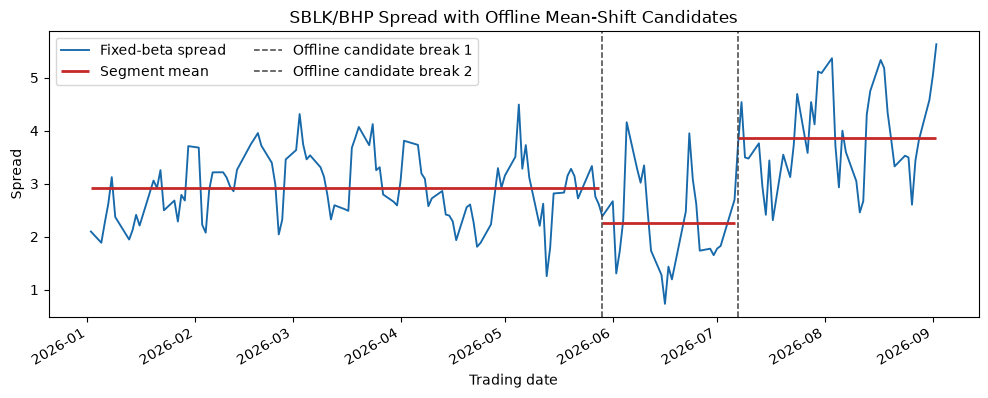

In [10]:
# Offline diagnostic only: locate two piecewise-constant mean shifts in the full sample.
spread_values = sblk_bhp['spread'].to_numpy(dtype=float)
dates = sblk_bhp['trade_date'].reset_index(drop=True)

def segment_sse(prefix_sum, prefix_square_sum, start, end):
    n = end - start
    total = prefix_sum[end] - prefix_sum[start]
    square_total = prefix_square_sum[end] - prefix_square_sum[start]
    return square_total - total * total / n

def best_two_mean_breaks(values, min_segment=20):
    prefix_sum = np.r_[0.0, np.cumsum(values)]
    prefix_square_sum = np.r_[0.0, np.cumsum(values ** 2)]
    n = len(values)
    best = (np.inf, None, None)
    for first_break in range(min_segment, n - 2 * min_segment + 1):
        for second_break in range(first_break + min_segment, n - min_segment + 1):
            sse = (segment_sse(prefix_sum, prefix_square_sum, 0, first_break)
                   + segment_sse(prefix_sum, prefix_square_sum, first_break, second_break)
                   + segment_sse(prefix_sum, prefix_square_sum, second_break, n))
            if sse < best[0]:
                best = (sse, first_break, second_break)
    return best

_, break_1, break_2 = best_two_mean_breaks(spread_values, min_segment=20)
segments = [(0, break_1), (break_1, break_2), (break_2, len(sblk_bhp))]
segment_summary = pd.DataFrame([
    {
        'segment': f'{start + 1}--{end}',
        'start': dates.iloc[start].date(),
        'end': dates.iloc[end - 1].date(),
        'observations': end - start,
        'mean': spread_values[start:end].mean(),
        'sigma': spread_values[start:end].std(ddof=1),
    }
    for start, end in segments
])
print('Offline candidate breaks:', dates.iloc[break_1].date(), dates.iloc[break_2].date())
print(segment_summary.round(4))

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(dates, spread_values, color='#1769aa', lw=1.35, label='Fixed-beta spread')
for segment_number, (start, end) in enumerate(segments, start=1):
    ax.hlines(spread_values[start:end].mean(), dates.iloc[start], dates.iloc[end - 1],
              color='#c62828', lw=2.0, label='Segment mean' if segment_number == 1 else None)
for index, label in [(break_1, 'Offline candidate break 1'), (break_2, 'Offline candidate break 2')]:
    ax.axvline(dates.iloc[index], color='#424242', ls='--', lw=1.1, label=label)
ax.set(title='SBLK/BHP Spread with Offline Mean-Shift Candidates', xlabel='Trading date', ylabel='Spread')
ax.legend(ncol=2)
fig.autofmt_xdate()
plt.show()


### 8.1 按约 20 个交易日分片，逐片计算 ADF

这里把 168 个交易日按顺序切成 20 日一片；最后不足 20 日的尾片保留，绝不为了凑整而丢数据。**每个切片都独立计算一次 ADF**，因此得到的是 9 个相邻小窗口的描述性结果，而非一个 60 日训练 / 20 日验证的流程。

`mean_shift_sigma` 定义为当前切片均值相对前一切片均值的变化，并以**前一切片的 sigma** 标准化：

$$ \mathrm{mean\_shift\_sigma}_j=\frac{\bar S_j-\bar S_{j-1}}{\hat\sigma_{j-1}} $$


这里的 `2 sigma gross-notional return` 是理论振幅容量：若在该片 $|Z|=2$ 入场、随后恰好回归 $Z=0$，则 spread P&L 为 $2\hat\sigma_S$；分母取该片双腿平均 gross notional：

$$ r_{2\sigma,j}=\frac{2\hat\sigma_{S,j}}{\overline{\mathrm{SBLK}+0.28\,\mathrm{BHP}}_j} $$

它不计成本、滑点、触发概率与未回归风险；因此是“每次理想回归能赚多少”的容量指标，而不是实际 PnL。
图中 mean shift 保留为“相对前片”的柱形变化；ADF p-value 与 2 sigma gross-notional return 则直接画每个完整切片的**绝对量**折线，避免比例变化掩盖它们本身的量纲。
第一片没有前片可比较，按约定设为 0。这个指标只回答“相邻两段的中心移动了多少个上一段的 sigma”，不等同于 ADF，也不是实时交易信号。最后不足 20 日的一片只保留其 constant-only OLS mean line；不计算、不绘制 ADF、p-value、2 sigma gross-notional return 或相对变化指标。


In [11]:
# Descriptive scan: one independent ADF calculation for each complete 20-trading-day slice.
SLICE_DAYS = 20
FIXED_ADF_LAG = 2
gross_notional_values = (sblk_bhp['SBLK'] + FIXED_BETA * sblk_bhp['BHP']).to_numpy(dtype=float)
scan_rows = []
previous_mean = None
previous_sigma = None
for slice_number, start in enumerate(range(0, len(spread_values), SLICE_DAYS), start=1):
    end = min(start + SLICE_DAYS, len(spread_values))
    current = spread_values[start:end]
    current_mean = current.mean()
    current_sigma = current.std(ddof=1)
    average_gross_notional = gross_notional_values[start:end].mean()
    is_complete_slice = len(current) == SLICE_DAYS
    if is_complete_slice:
        feasible_lag = min(FIXED_ADF_LAG, max(0, len(current) // 3 - 1))
        adf_stat, adf_pvalue, used_lag, _, *_ = adfuller(
            current, maxlag=feasible_lag, autolag=None, regression='c'
        )
        two_sigma_gross_notional_return = 2 * current_sigma / average_gross_notional
        mean_shift_sigma = 0.0 if previous_mean is None else (current_mean - previous_mean) / previous_sigma
    else:
        adf_stat = adf_pvalue = used_lag = two_sigma_gross_notional_return = mean_shift_sigma = np.nan
    scan_rows.append({
        'slice': slice_number,
        'start': dates.iloc[start].date(),
        'end': dates.iloc[end - 1].date(),
        'observations': len(current),
        'complete_20_bar_slice': is_complete_slice,
        'adf_stat': adf_stat,
        'adf_pvalue': adf_pvalue,
        'adf_lag': used_lag,
        'mean': current_mean,
        'sigma': current_sigma,
        'average_gross_notional': average_gross_notional,
        'mean_shift_sigma_vs_previous_slice': mean_shift_sigma,
        'two_sigma_gross_notional_return': two_sigma_gross_notional_return,
    })
    previous_mean, previous_sigma = current_mean, current_sigma

slice_scan = pd.DataFrame(scan_rows)
complete_slice_scan = slice_scan.loc[slice_scan['complete_20_bar_slice']].copy()
print(slice_scan.round(4).to_string(index=False))


 slice      start        end  observations  complete_20_bar_slice  adf_stat  adf_pvalue  adf_lag   mean  sigma  average_gross_notional  mean_shift_sigma_vs_previous_slice  two_sigma_gross_notional_return
     1 2026-01-02 2026-01-30            20                   True   -2.6586      0.0815      2.0 2.5493 0.4824                 39.3547                              0.0000                           0.0245
     2 2026-02-02 2026-03-02            20                   True   -1.9385      0.3142      2.0 3.1289 0.5917                 45.2431                              1.2015                           0.0262
     3 2026-03-03 2026-03-30            20                   True   -2.0009      0.2862      2.0 3.2838 0.6030                 43.0262                              0.2619                           0.0280
     4 2026-03-31 2026-04-28            20                   True   -2.0377      0.2703      2.0 2.6388 0.5438                 46.0052                             -1.0697              

/tmp/ipykernel_3273627/2159907624.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


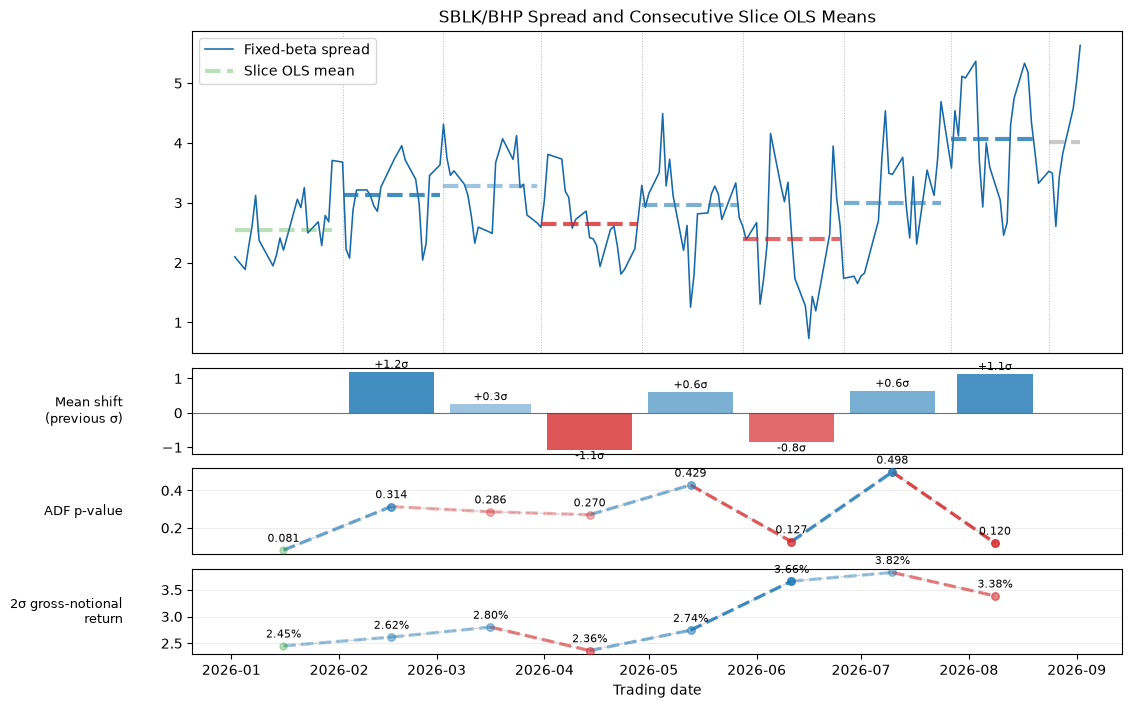

In [12]:
# Aligned slice diagnostic: the incomplete final slice only retains its OLS mean line.
import matplotlib.dates as mdates

fig, axes = plt.subplots(
    4, 1, figsize=(12, 8.1), sharex=True,
    gridspec_kw={'height_ratios': [2.7, 0.72, 0.72, 0.72], 'hspace': 0.10}
)
ax_spread, ax_mean_shift, ax_pvalue, ax_two_sigma_return = axes

def signed_rgba(value, scale, incomplete=False):
    if incomplete:
        return (0.35, 0.35, 0.35, 0.32)
    if value > 0:
        base = (0.12, 0.47, 0.71)  # blue: increase
    elif value < 0:
        base = (0.84, 0.15, 0.16)  # red: decrease
    else:
        base = (0.17, 0.63, 0.17)  # green: unchanged
    alpha = 0.32 + 0.52 * min(abs(value) / scale, 1.0) if scale > 0 else 0.55
    return (*base, alpha)

complete_shift_scale = complete_slice_scan['mean_shift_sigma_vs_previous_slice'].abs().max()
ax_spread.plot(dates, spread_values, color='#1769aa', lw=1.15, label='Fixed-beta spread')
for row in slice_scan.itertuples(index=False):
    start_date, end_date = pd.Timestamp(row.start), pd.Timestamp(row.end)
    line_color = signed_rgba(0 if not row.complete_20_bar_slice else row.mean_shift_sigma_vs_previous_slice,
                             complete_shift_scale, incomplete=not row.complete_20_bar_slice)
    ax_spread.hlines(row.mean, start_date, end_date, color=line_color, lw=3.0, ls='--',
                     label='Slice OLS mean' if row.slice == 1 else None)
    if row.slice > 1:
        ax_spread.axvline(start_date, color='#616161', ls=':', lw=0.7, alpha=0.45)
ax_spread.set(title='SBLK/BHP Spread and Consecutive Slice OLS Means', ylabel='Spread')
ax_spread.legend(loc='upper left')

def slice_center_and_width(row):
    start_number = mdates.date2num(pd.Timestamp(row.start))
    end_number = mdates.date2num(pd.Timestamp(row.end))
    return (start_number + end_number) / 2, max(1.0, (end_number - start_number + 1) * 0.84)

change_rows = complete_slice_scan.iloc[1:]
def draw_mean_shift(ax):
    values = change_rows['mean_shift_sigma_vs_previous_slice']
    scale = values.abs().max()
    centers, widths = zip(*(slice_center_and_width(row) for row in change_rows.itertuples(index=False)))
    colors = [signed_rgba(value, scale) for value in values]
    ax.bar(centers, values, width=widths, color=colors, edgecolor='none', align='center')
    ax.axhline(0, color='#424242', lw=0.8, alpha=0.75)
    ax.text(-0.075, 0.5, 'Mean shift\n(previous σ)', transform=ax.transAxes, ha='right', va='center', fontsize=9)
    for center, value in zip(centers, values):
        offset = max(0.025 * scale, 0.02) * (1 if value >= 0 else -1)
        ax.text(center, value + offset, f'{value:+.1f}σ', ha='center',
                va='bottom' if value >= 0 else 'top', fontsize=8)

def draw_absolute_line(ax, column, left_label, scale, suffix, decimals):
    values = complete_slice_scan[column].to_numpy(dtype=float) * scale
    centers = [slice_center_and_width(row)[0] for row in complete_slice_scan.itertuples(index=False)]
    changes = np.diff(values)
    change_scale = np.max(np.abs(changes)) if len(changes) else 1.0
    ax.plot(centers, values, color=(0.30, 0.30, 0.30, 0.22), ls='--', lw=1.0)
    ax.scatter(centers[0], values[0], color=signed_rgba(0, change_scale), s=26, zorder=3)
    for i in range(1, len(values)):
        color = signed_rgba(changes[i - 1], change_scale)
        ax.plot(centers[i - 1:i + 1], values[i - 1:i + 1], color=color, lw=2.4, ls='--')
        ax.scatter(centers[i], values[i], color=color, s=30, zorder=3)
    ax.text(-0.075, 0.5, left_label, transform=ax.transAxes, ha='right', va='center', fontsize=9)
    for center, value in zip(centers, values):
        ax.annotate(f'{value:.{decimals}f}{suffix}', xy=(center, value), xytext=(0, 6),
                    textcoords='offset points', ha='center', fontsize=8)
    ax.grid(axis='y', color='#9e9e9e', lw=0.5, alpha=0.25)

draw_mean_shift(ax_mean_shift)
draw_absolute_line(ax_pvalue, 'adf_pvalue', 'ADF p-value', scale=1, suffix='', decimals=3)
draw_absolute_line(ax_two_sigma_return, 'two_sigma_gross_notional_return',
                   '2σ gross-notional\nreturn', scale=100, suffix='%', decimals=2)
for ax in axes[:-1]:
    ax.tick_params(axis='x', which='both', length=0, labelbottom=False)
    ax.set_ylabel('')
ax_two_sigma_return.xaxis.set_major_locator(mdates.MonthLocator())
ax_two_sigma_return.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax_two_sigma_return.set(xlabel='Trading date', ylabel='')
fig.tight_layout()
plt.show()


### 8.2 NKE/XPO：复现当时 80-bar scanner，并统一为 20-bar 分片

这一节严格复现结果文件 `adf_80d_active_pairs_adf3_20260726_133631.csv` 中的 scanner 记录：

$$ \mathrm{train}=\text{2026-03-31 to 2026-07-24},\qquad n=80 $$

$$ \beta=0.0652434588,\qquad a=29.9352789140 $$

$$ S_t=\mathrm{NKE}_t-(a+\beta\,\mathrm{XPO}_t) $$

全窗重算 ADF 必须与保存的 scanner 记录一致。我们仍可在该 spread 上扫描正弦候选周期，作为“是否存在明显短周期摆动”的描述性诊断；本例最强候选约 14 bars，但解释度只有 $R^2\approx0.245$，不够强到让它决定生产窗口。

因此为与第 8.1 节和 scanner workflow 保持一致，**统一使用 20 个交易日切片**：80 bars 恰好得到 4 个完整切片。20-bar 局部 ADF 仅描述局部状态；真正的资格检验仍是完整 80-bar scanner ADF。

2 sigma gross-notional return 复用 scanner 口径：理想回归 P&L 为 $2\hat\sigma_S$，分母取每片最后一天的 $\mathrm{NKE}+|\beta|\,\mathrm{XPO}$。


In [13]:
# Exact saved scanner definition for NKE/XPO.
NKE_XPO_TRAIN_START = '2026-03-31'
NKE_XPO_TRAIN_END = '2026-07-24'
NKE_XPO_SCAN_BETA = 0.06524345878115628
NKE_XPO_SCAN_INTERCEPT = 29.935278914033123
NKE_XPO_SCAN_ADF_STAT = -8.467697602829766
NKE_XPO_SCAN_ADF_PVALUE = 1.5068236292286827e-13
nke_xpo_sql = '''
    SELECT y.trade_date, y.price AS NKE, x.price AS XPO
    FROM us_market_days AS y
    JOIN us_market_days AS x ON x.trade_date = y.trade_date AND x.ticker = 'XPO'
    WHERE y.ticker = 'NKE' AND y.trade_date >= %s AND y.trade_date <= %s
    ORDER BY y.trade_date
'''
conn = pymysql.connect(**DB_CONFIG)
try:
    nke_xpo = pd.read_sql(nke_xpo_sql, conn, params=(NKE_XPO_TRAIN_START, NKE_XPO_TRAIN_END))
finally:
    conn.close()
nke_xpo['trade_date'] = pd.to_datetime(nke_xpo['trade_date'])
nke_xpo[['NKE', 'XPO']] = nke_xpo[['NKE', 'XPO']].apply(pd.to_numeric)
assert len(nke_xpo) == 80
nke_xpo['spread'] = nke_xpo['NKE'] - (NKE_XPO_SCAN_INTERCEPT + NKE_XPO_SCAN_BETA * nke_xpo['XPO'])
nke_xpo['gross_notional'] = nke_xpo['NKE'] + abs(NKE_XPO_SCAN_BETA) * nke_xpo['XPO']
nke_xpo_values = nke_xpo['spread'].to_numpy(dtype=float)
nke_xpo_dates = nke_xpo['trade_date'].reset_index(drop=True)
full_adf_stat, full_adf_pvalue, full_adf_lag, full_adf_nobs, *_ = adfuller(nke_xpo_values, autolag='AIC')
print(f'80-bar scanner beta={NKE_XPO_SCAN_BETA:.6f}, intercept={NKE_XPO_SCAN_INTERCEPT:.6f}')
print(f'Recomputed ADF={full_adf_stat:.6f}, p={full_adf_pvalue:.4g}, lag={full_adf_lag}')
assert np.isclose(full_adf_stat, NKE_XPO_SCAN_ADF_STAT)

# Profile one sine wave at each candidate period; this chooses a diagnostic slice length only.
cycle_rows = []
t = np.arange(len(nke_xpo_values), dtype=float)
total_sse = np.sum((nke_xpo_values - nke_xpo_values.mean()) ** 2)
for period in range(8, 41):
    design = np.column_stack([np.ones(len(t)), np.sin(2 * np.pi * t / period), np.cos(2 * np.pi * t / period)])
    fitted = design @ np.linalg.lstsq(design, nke_xpo_values, rcond=None)[0]
    cycle_rows.append({'period_bars': period, 'sine_r_squared': 1 - np.sum((nke_xpo_values - fitted) ** 2) / total_sse})
cycle_candidates = pd.DataFrame(cycle_rows)
NKE_XPO_DOMINANT_CYCLE_BARS = int(cycle_candidates.loc[cycle_candidates['sine_r_squared'].idxmax(), 'period_bars'])
NKE_XPO_SLICE_DAYS = 20
acf_at_cycle = float(np.corrcoef(nke_xpo_values[:-NKE_XPO_DOMINANT_CYCLE_BARS], nke_xpo_values[NKE_XPO_DOMINANT_CYCLE_BARS:])[0, 1])
print(f'Dominant sine-cycle candidate: {NKE_XPO_DOMINANT_CYCLE_BARS} bars; ACF at that lag={acf_at_cycle:.3f}; using fixed 20-bar slices')
print(cycle_candidates.sort_values('sine_r_squared', ascending=False).head(5).round(4).to_string(index=False))

nke_xpo_rows = []
previous_mean = previous_sigma = None
for slice_number, start in enumerate(range(0, len(nke_xpo), NKE_XPO_SLICE_DAYS), start=1):
    end = min(start + NKE_XPO_SLICE_DAYS, len(nke_xpo))
    current = nke_xpo_values[start:end]
    current_mean, current_sigma = current.mean(), current.std(ddof=1)
    complete = len(current) == NKE_XPO_SLICE_DAYS
    if complete:
        maxlag = min(3, len(current) // 2 - 2)
        adf_stat, adf_pvalue, used_lag, _, *_ = adfuller(current, maxlag=maxlag, autolag='AIC', regression='c')
        two_sigma_return = 2 * current_sigma / nke_xpo['gross_notional'].iloc[end - 1]
        mean_shift = 0.0 if previous_mean is None else (current_mean - previous_mean) / previous_sigma
    else:
        adf_stat = adf_pvalue = used_lag = two_sigma_return = mean_shift = np.nan
    nke_xpo_rows.append({'slice': slice_number, 'start': nke_xpo_dates.iloc[start].date(), 'end': nke_xpo_dates.iloc[end-1].date(),
                         'observations': len(current), 'complete_cycle_slice': complete, 'adf_stat': adf_stat,
                         'adf_pvalue': adf_pvalue, 'adf_lag': used_lag, 'mean': current_mean, 'sigma': current_sigma,
                         'mean_shift_sigma_vs_previous_slice': mean_shift, 'two_sigma_gross_notional_return': two_sigma_return})
    previous_mean, previous_sigma = current_mean, current_sigma
nke_xpo_slice_scan = pd.DataFrame(nke_xpo_rows)
nke_xpo_complete_slices = nke_xpo_slice_scan.loc[nke_xpo_slice_scan['complete_cycle_slice']].copy()
print(nke_xpo_slice_scan.round(4).to_string(index=False))


80-bar scanner beta=0.065243, intercept=29.935279
Recomputed ADF=-8.467698, p=1.507e-13, lag=0
Dominant sine-cycle candidate: 14 bars; ACF at that lag=0.318; using fixed 20-bar slices
 period_bars  sine_r_squared
          14          0.2452
          13          0.1840
          18          0.1327
          17          0.1209
          15          0.0817
 slice      start        end  observations  complete_cycle_slice  adf_stat  adf_pvalue  adf_lag    mean  sigma  mean_shift_sigma_vs_previous_slice  two_sigma_gross_notional_return
     1 2026-03-31 2026-04-28            20                  True  -10.0239      0.0000        0  0.7155 2.2956                              0.0000                           0.0777
     2 2026-04-29 2026-05-27            20                  True   -0.8973      0.7889        0 -0.2073 0.9336                             -0.4020                           0.0314
     3 2026-05-28 2026-06-25            20                  True   -1.9527      0.3077        0  0.262

/tmp/ipykernel_3273627/3199408189.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  nke_xpo = pd.read_sql(nke_xpo_sql, conn, params=(NKE_XPO_TRAIN_START, NKE_XPO_TRAIN_END))


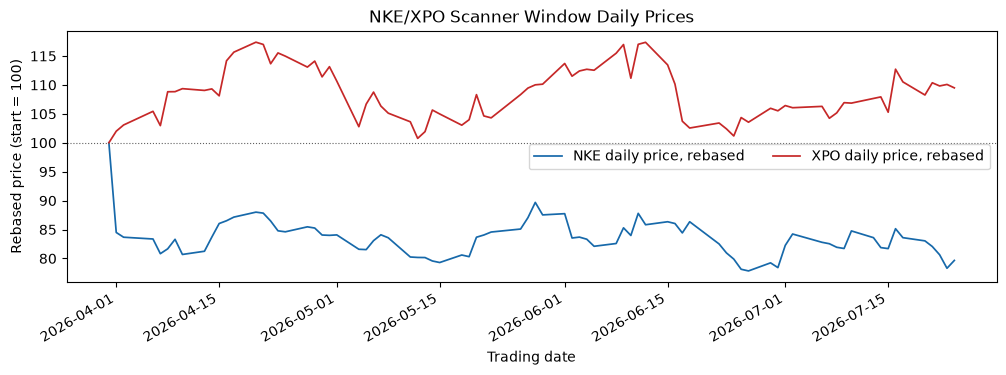

In [14]:
# The exact 80-bar scanner window, with daily prices rebased for comparison.
rebased = nke_xpo.set_index('trade_date')[['NKE', 'XPO']].div(nke_xpo[['NKE', 'XPO']].iloc[0]).mul(100)
fig, ax = plt.subplots(figsize=(12, 3.7))
ax.plot(rebased.index, rebased['NKE'], color='#1769aa', lw=1.25, label='NKE daily price, rebased')
ax.plot(rebased.index, rebased['XPO'], color='#c62828', lw=1.25, label='XPO daily price, rebased')
ax.axhline(100, color='#616161', lw=.8, ls=':')
ax.set(title='NKE/XPO Scanner Window Daily Prices', xlabel='Trading date', ylabel='Rebased price (start = 100)')
ax.legend(ncol=2); fig.autofmt_xdate(); plt.show()


/tmp/ipykernel_3273627/112661436.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(); plt.show()


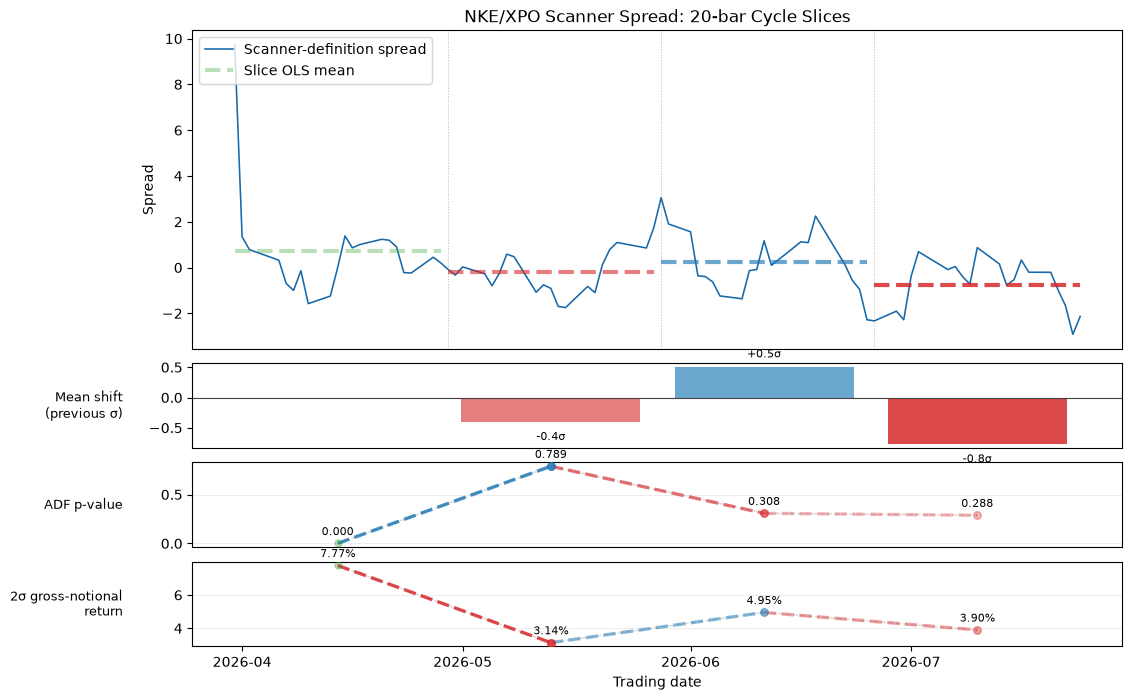

In [15]:
# Cycle-length slice diagnostics, aligned on the exact scanner-window date axis.
import matplotlib.dates as mdates
fig, axes = plt.subplots(4, 1, figsize=(12, 8.0), sharex=True, gridspec_kw={'height_ratios': [2.7, .72, .72, .72], 'hspace': .10})
ax_spread, ax_shift, ax_pvalue, ax_return = axes
def nke_xpo_color(value, scale, incomplete=False):
    if incomplete: return (.35, .35, .35, .32)
    base = (.12, .47, .71) if value > 0 else ((.84, .15, .16) if value < 0 else (.17, .63, .17))
    return (*base, .32 + .52 * min(abs(value) / scale, 1) if scale > 0 else .55)
def nke_xpo_center_width(row):
    left, right = mdates.date2num(pd.Timestamp(row.start)), mdates.date2num(pd.Timestamp(row.end))
    return (left + right) / 2, max(1., (right - left + 1) * .84)
shift_scale = nke_xpo_complete_slices['mean_shift_sigma_vs_previous_slice'].abs().max()
ax_spread.plot(nke_xpo_dates, nke_xpo_values, color='#1769aa', lw=1.15, label='Scanner-definition spread')
for row in nke_xpo_slice_scan.itertuples(index=False):
    color = nke_xpo_color(0 if not row.complete_cycle_slice else row.mean_shift_sigma_vs_previous_slice, shift_scale, not row.complete_cycle_slice)
    ax_spread.hlines(row.mean, pd.Timestamp(row.start), pd.Timestamp(row.end), color=color, lw=3, ls='--', label='Slice OLS mean' if row.slice == 1 else None)
    if row.slice > 1: ax_spread.axvline(pd.Timestamp(row.start), color='#616161', ls=':', lw=.7, alpha=.45)
ax_spread.set(title=f'NKE/XPO Scanner Spread: {NKE_XPO_SLICE_DAYS}-bar Cycle Slices', ylabel='Spread'); ax_spread.legend(loc='upper left')
change_rows = nke_xpo_complete_slices.iloc[1:]
centers, widths = zip(*(nke_xpo_center_width(row) for row in change_rows.itertuples(index=False)))
shift_values = change_rows['mean_shift_sigma_vs_previous_slice'].to_numpy()
ax_shift.bar(centers, shift_values, width=widths, color=[nke_xpo_color(v, shift_scale) for v in shift_values], edgecolor='none'); ax_shift.axhline(0, color='#424242', lw=.8)
ax_shift.text(-.075, .5, 'Mean shift\n(previous σ)', transform=ax_shift.transAxes, ha='right', va='center', fontsize=9)
for center, value in zip(centers, shift_values): ax_shift.annotate(f'{value:+.1f}σ', xy=(center,value), xytext=(0,5 if value>=0 else -7), textcoords='offset points', ha='center', va='bottom' if value>=0 else 'top', fontsize=8)
def nke_xpo_absolute_line(ax, column, label, scale, suffix, decimals):
    values = nke_xpo_complete_slices[column].to_numpy(float) * scale; x = [nke_xpo_center_width(row)[0] for row in nke_xpo_complete_slices.itertuples(index=False)]
    changes = np.diff(values); change_scale = max(np.max(abs(changes)), 1e-12)
    ax.plot(x, values, color=(.3,.3,.3,.22), ls='--', lw=1); ax.scatter(x[0],values[0],color=nke_xpo_color(0,change_scale),s=26,zorder=3)
    for i in range(1,len(values)):
        color=nke_xpo_color(changes[i-1],change_scale); ax.plot(x[i-1:i+1],values[i-1:i+1],color=color,lw=2.4,ls='--'); ax.scatter(x[i],values[i],color=color,s=30,zorder=3)
    ax.text(-.075,.5,label,transform=ax.transAxes,ha='right',va='center',fontsize=9)
    for center,value in zip(x,values): ax.annotate(f'{value:.{decimals}f}{suffix}',xy=(center,value),xytext=(0,6),textcoords='offset points',ha='center',fontsize=8)
    ax.grid(axis='y',color='#9e9e9e',lw=.5,alpha=.25)
nke_xpo_absolute_line(ax_pvalue,'adf_pvalue','ADF p-value',1,'',3)
nke_xpo_absolute_line(ax_return,'two_sigma_gross_notional_return','2σ gross-notional\nreturn',100,'%',2)
for ax in axes[:-1]: ax.tick_params(axis='x',which='both',length=0,labelbottom=False)
ax_return.xaxis.set_major_locator(mdates.MonthLocator()); ax_return.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m')); ax_return.set(xlabel='Trading date')
fig.tight_layout(); plt.show()


### 8.3 让执行层使用 causal rolling mean，再检验它是否跨越台阶仍工作

下面的 $z_t$ 用截至 $t$ 的 20 日窗口计算；在日线回测中应把这个收盘后才完整可见的信号放到下一根 bar 执行，避免同一收盘价成交造成 look-ahead。红色虚线只是事后研究的候选断点，**不是**在线交易指令。

关键的边界是：不要对 $S_t-\operatorname{RollingMean}_t(S)$ 或 rolling z-score 再直接报告 ADF p-value，仿佛那仍是原 spread 的单位根问题。rolling filter 会主动移除低频水平成分，改变检验对象，甚至会令随机游走看起来更像平稳过程。ADF / Engle--Granger 资格检验仍应在预先规定、未作 rolling 去均值的训练 spread（或价格协整回归）上进行；rolling mean 属于后续的执行坐标系。


          offline_regime  observations  mean_abs_z  signal_rate_abs_z_ge_1  signal_rate_abs_z_ge_2
Before candidate break 1            82       0.918                  0.4390                  0.0244
Between candidate breaks            25       0.951                  0.3600                  0.0800
 After candidate break 2            42       0.941                  0.4524                  0.0238


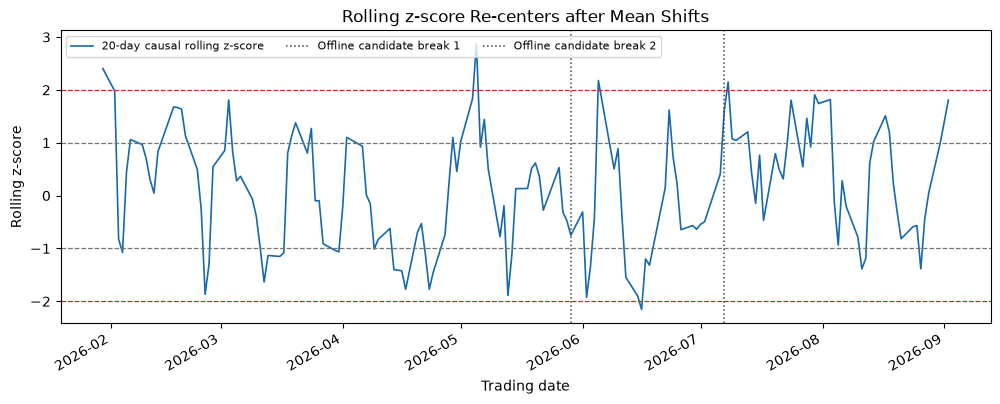

In [16]:
# Execution-layer diagnostic: all rolling inputs are available by the end of each trading day.
ROLLING_WINDOW = 20
live = sblk_bhp[['trade_date', 'spread']].copy()
live['rolling_mean'] = live['spread'].rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).mean()
live['rolling_sigma'] = live['spread'].rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW).std(ddof=1)
live['causal_z'] = (live['spread'] - live['rolling_mean']) / live['rolling_sigma']

# These labels are deliberately offline diagnostics, not real-time information.
live['offline_regime'] = np.select(
    [live.index < break_1, live.index < break_2],
    ['Before candidate break 1', 'Between candidate breaks'],
    default='After candidate break 2',
)
rolling_resilience = (live.dropna(subset=['causal_z'])
    .groupby('offline_regime', sort=False)
    .agg(
        observations=('causal_z', 'size'),
        mean_abs_z=('causal_z', lambda x: x.abs().mean()),
        signal_rate_abs_z_ge_1=('causal_z', lambda x: (x.abs() >= 1).mean()),
        signal_rate_abs_z_ge_2=('causal_z', lambda x: (x.abs() >= 2).mean()),
    )
    .reset_index())
print(rolling_resilience.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 4.3))
ax.plot(live['trade_date'], live['causal_z'], color='#1769aa', lw=1.2, label='20-day causal rolling z-score')
for level, color in [(1, '#757575'), (2, '#c62828')]:
    ax.axhline(level, color=color, ls='--', lw=0.9)
    ax.axhline(-level, color=color, ls='--', lw=0.9)
for idx, label in [(break_1, 'Offline candidate break 1'), (break_2, 'Offline candidate break 2')]:
    ax.axvline(dates.iloc[idx], color='#424242', ls=':', lw=1.1, label=label)
ax.set(title='Rolling z-score Re-centers after Mean Shifts', xlabel='Trading date', ylabel='Rolling z-score')
ax.legend(ncol=3, fontsize=8)
fig.autofmt_xdate()
plt.show()
